**REDES TENSORIALES EN MACHINE LEARNING**

Las Redes Tensoriales (Tensor Networks, TN) son una familia de modelos matemáticos desarrollados originalmente en física cuántica para representar sistemas de muy alta dimensión de forma eficiente. En Machine Learning permiten descomponer tensores de gran tamaño en una red de tensores pequeños, reduciendo drásticamente el número de parámetros y el coste computacional.

Aunque actualmente no sustituyen a arquitecturas dominantes como los Transformers, constituyen una línea de investigación muy activa por su capacidad para construir modelos más eficientes, interpretables y escalables, especialmente en aplicaciones científicas y de computación cuántica.

Principales ventajas:

-Compresión de modelos de Deep Learning.

-Reducción del consumo de memoria y energía.

-Inferencia más eficiente.

-Mejor interpretación de las correlaciones entre variables.

-Conexión natural con la computación cuántica y la física estadística.

Líneas a investigar:

-**Quantum Machine Learning**: los circuitos cuánticos pueden representarse como Tensor Networks, lo que permite: simular circuitos cuánticos, estudiar la expresividad de redes cuánticas, analizar el entrelazamiento (entanglement),
optimizar circuitos variacionales.

-**Quantized Tensor Train o Quantics Tensor Train**: reorganiza vectores o matrices de gran tamaño como tensores de muchas dimensiones pequeñas antes de aplicar la descomposición TT. Esto permite obtener representaciones extremadamente compactas, reduciendo significativamente la memoria y el coste computacional. Es una técnica clave en simulación de sistemas cuánticos, resolución de problemas de alta dimensión y algoritmos quantum-inspired.



**SOLUCIÓN DEL ARTÍCULO PROBLEMAS DE REGRESIÓN**. Primeramente se realiza el código correspondinte a los problemas presentados en el artículo, para comprarar posteriormente los resultados con los de la representaciñón QUANTICS


In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!pip install dwave-neal

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 38.8 MB/s eta 0:00:00


# **Encoding 2**: Se desarrolla la codificación del artículo 𝚀𝚄𝙱𝙾 for training regression models

In [ ]:
def build_encoding_vector(alpha, beta):
    """
    Construye el vector extendido del encoding #2.
    alpha=2, beta=0 potencias:[2^0, 2^-1, 2^-2]
    Nw = suma = 1 + 0.5 + 0.25 = 1.75
    vector:[-1.75, 1, 0.5, 0.25]
    """
    powers = [2**t for t in range(beta, -alpha - 1, -1)]
    Nw = sum(powers)

    return np.array([-Nw] + powers)

Construcción T y QUBO

In [ ]:
def build_T(m, encoding_vector):
    return np.kron(np.eye(m), encoding_vector)
def build_qubo(Phi, y, T):
    Lambda = Phi @ Phi.T
    p = Phi @ y

    Q = T.T @ Lambda @ T
    w = 2 * (T.T @ p)

    Q_tilde = Q - np.diag(w)

    return Q_tilde

Solver QUBO brute force:  Minimiza: u^T Q u probando todas las configuraciones binarias.

In [ ]:
def solve_qubo_bruteforce(Q):
    n = Q.shape[0]

    best_energy = np.inf
    best_u = None

    for bits in itertools.product([0, 1], repeat=n):
        u = np.array(bits)

        energy = u.T @ Q @ u

        if energy < best_energy:
            best_energy = energy
            best_u = u

    return best_u, best_energy

Decodificación

In [ ]:
def decode_solution(T, u):
    return T @ u

# **Problema 1**: primera función que se presenta en el artículo

Solución analítica:
[ 0.75 -1.75]
Encoding vector:
[-1.75  1.    0.5   0.25]
u* =
[0 0 1 1 1 0 0 0]
Energy = -24.875
Solución QUBO:
[ 0.75 -1.75]


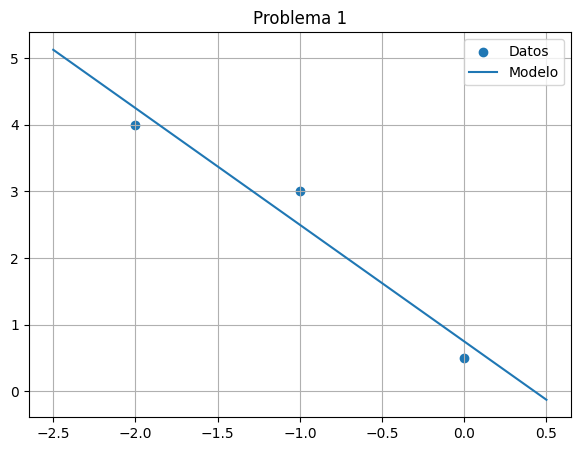

In [ ]:
X1 = np.array([0, -1, -2])
y1 = np.array([0.5, 3, 4])
Phi1 = np.array([
    [1, 1, 1],
    [0, -1, -2]
])
q_analytic_1 = np.linalg.inv(Phi1 @ Phi1.T) @ Phi1 @ y1

print("Solución analítica:")
print(q_analytic_1)
#QUBO
alpha = 2
beta = 0

encoding_vector = build_encoding_vector(alpha, beta)

print("Encoding vector:")
print(encoding_vector)
m1 = 2 #parametros
T1 = build_T(m1, encoding_vector)
Q1 = build_qubo(Phi1, y1, T1)
u1, energy1 = solve_qubo_bruteforce(Q1)

print("u* =")
print(u1)

print("Energy =", energy1)
q_qubo_1 = decode_solution(T1, u1)

print("Solución QUBO:")
print(q_qubo_1)
x_plot = np.linspace(-2.5, 0.5, 200)

y_plot = q_qubo_1[0] + q_qubo_1[1] * x_plot

plt.figure(figsize=(7,5))
plt.scatter(X1, y1, label="Datos")
plt.plot(x_plot, y_plot, label="Modelo")
plt.legend()
plt.grid(True)
plt.title("Problema 1")
plt.show()

# **Problema 2**: segunda función que se presneta en el artículo

In [ ]:
N = 300
x2 = np.arange(N) / N
epsilon = 1e-1
noise = np.random.uniform(-epsilon, epsilon, size=N)
y2 = (
    0.5
    + 0.25 * np.sin(2 * np.pi * x2)
    + 0.125 * np.sin(4 * np.pi * x2)
    + 0.125 * np.sin(6 * np.pi * x2)
    + noise
)
Phi2 = np.array([
    np.ones(N),
    np.sin(2 * np.pi * x2),
    np.sin(4 * np.pi * x2),
    np.sin(6 * np.pi * x2)
])
q_analytic_2 = np.linalg.inv(Phi2 @ Phi2.T) @ Phi2 @ y2

print("Solución analítica:")
print(q_analytic_2)
alpha2 = 3
beta2 = 1

encoding_vector2 = build_encoding_vector(alpha2, beta2)
print(encoding_vector2)
m2 = 4 #numero parametros
T2 = build_T(m2, encoding_vector2)
Q2 = build_qubo(Phi2, y2, T2)



Solución analítica:
[0.49465081 0.2531826  0.1282215  0.12528096]
[-3.875  2.     1.     0.5    0.25   0.125]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 50.1 MB/s eta 0:00:00
Solución QUBO:
[0.5   0.25  0.125 0.125]


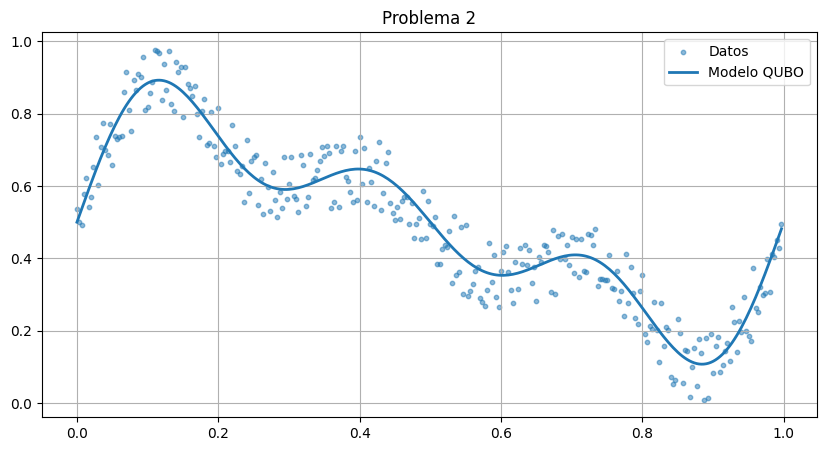

In [ ]:
#D-Wave

import neal

sampler = neal.SimulatedAnnealingSampler()

sampleset = sampler.sample_qubo(
    {(i, j): Q2[i, j]
     for i in range(Q2.shape[0])
     for j in range(Q2.shape[1])
     if Q2[i, j] != 0},
    num_reads=500
)

best_sample = sampleset.first.sample

u2 = np.array([best_sample[i] for i in range(len(best_sample))])
q_qubo_2 = decode_solution(T2, u2)

print("Solución QUBO:")
print(q_qubo_2)
plt.figure(figsize=(10,5))

plt.scatter(x2, y2, s=10, alpha=0.5, label="Datos")

pred = (
    q_qubo_2[0]
    + q_qubo_2[1] * np.sin(2 * np.pi * x2)
    + q_qubo_2[2] * np.sin(4 * np.pi * x2)
    + q_qubo_2[3] * np.sin(6 * np.pi * x2)
)

plt.plot(x2, pred, linewidth=2, label="Modelo QUBO")

plt.legend()
plt.grid(True)
plt.title("Problema 2")
plt.show()

# **QUANTICS REPRESENTATION**. Inspirado en el artículo S*imulating Quantum Turbulence with Matrix Product State*s.

Codifica funciones en el espacio real (continuas) mediante una **estructura tensorial comprimida**. Cada componente de dos niveles representa una escala de longitud específica. Se define un **grid de 2^N puntos**. En lugar de representar cada muestra mediante un único índice entero, dicho índice se expresa en formato binario. Por ejemplo, si se utilizan N=10 bits, se obtienen (2^10=1024) puntos de discretización. De esta forma, cada muestra queda representada mediante una secuencia binaria de longitud diez. Este procedimiento permite reinterpretar un vector unidimensional de datos como un tensor de orden elevado cuyas dimensiones son binarias.

Sobre esta representación tensorial se construye un modelo** Matrix Product State (MPS)**, también conocido en aprendizaje automático como **Tensor Train (TT**). Un MPS descompone un tensor de gran tamaño en una secuencia de tensores pequeños denominados cores. Cada tensor interno está conectado con sus vecinos mediante índices virtuales cuya dimensión se controla mediante el parámetro denominado **bond dimension**. Este parámetro determina la capacidad expresiva del modelo. Valores pequeños producen modelos más simples y compactos, mientras que valores mayores permiten capturar dependencias y patrones más complejos presentes en los datos.

El bond dimension  es un hiperparámetro interno que define el tamaño de las matrices que conectan los tensores. Puede ser cualquier número entero positivo. Sin embargo, en Deep Learning se suele usar potencias de dos (16, 32, 64) simplemente porque las tarjetas gráficas (GPUs) procesan las matrices en potencias de dos de forma ligeramente más rápida y optimizada.

Se utiliza el **optimizador Adam**. Sin embargo, en lugar de actualizar simultáneamente todos los parámetros, se sigue una estrategia inspirada en el algoritmo Density Matrix Renormalization Group (DMRG).
Aunque las estructuras MPS y el algoritmo DMRG fueron desarrollados originalmente para estudiar sistemas cuánticos de muchos cuerpos, en este trabajo no se emplea hardware cuántico ni qubits físicos. La ejecución se realiza íntegramente sobre p**rocesadores clásicos (PyTorch)**. La relación con la computación cuántica radica únicamente en el origen matemático de las técnicas utilizadas, que han demostrado ser también herramientas muy eficaces para compresión de datos, aproximación funcional y aprendizaje automático.


Se prueba con la segunda función para ver si la predice de forma correcta.


**Aprender una función periódica con ruido usando una representación MPS (Matrix Product State o Tensor Train) y un entrenamiento tipo DMRG.**

Pipeline:

Quantics encoding — el índice $i\in\{0,..,M-1\}$ se codifica en su representación binaria $(n_1, n_2, \ldots, n_{10}) \in \{0,1\}^{10}$, convirtiendo la función en un tensor de rango 10 con dimensión física 2.

MPS (Matrix Product State) — el tensor se parametriza como un producto de matrices $A_1[n_1] A_2[n_2] \cdots A_{10}[n_{10}]$, con bond_dim=8 (dimensión de enlace) como hiperparámetro que controla la expresividad.

Entrenamiento DMRG-like — sweeps izquierda→derecha y derecha→izquierda, optimizando un core a la vez con Adam.

Finalmente se evalúa el rendimiento calculando el **error cuadrático medio** respecto a la función exacta y representando gráficamente tanto los datos originales como la aproximación obtenida por el MPS.

Sweep   0 | Loss = 0.00880263
Sweep   1 | Loss = 0.00429946
Sweep   2 | Loss = 0.00395455
Sweep   3 | Loss = 0.00379160
Sweep   4 | Loss = 0.00362250
Sweep   5 | Loss = 0.00344460
Sweep   6 | Loss = 0.00334717
Sweep   7 | Loss = 0.00330380
Sweep   8 | Loss = 0.00327452
Sweep   9 | Loss = 0.00324835

MSE final: 3.47070544e-04


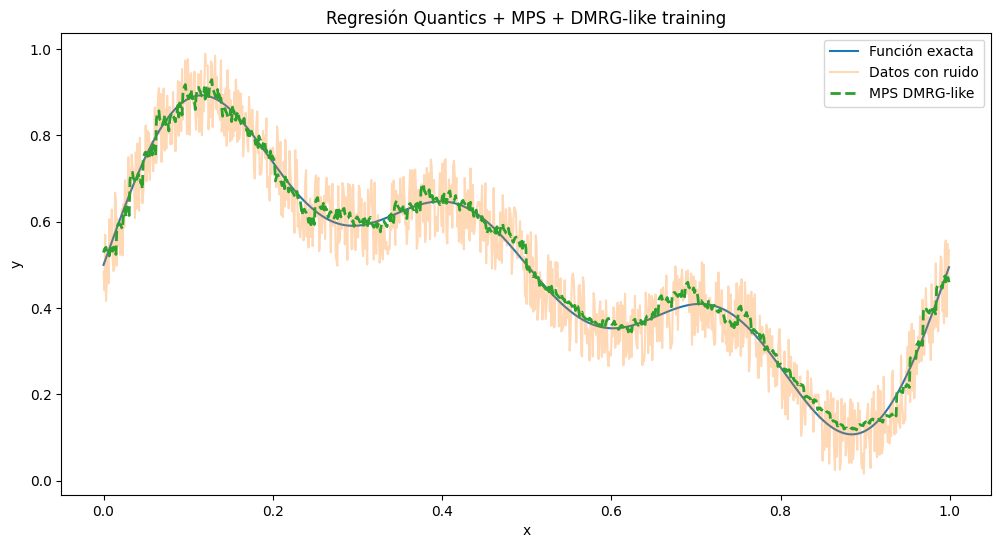

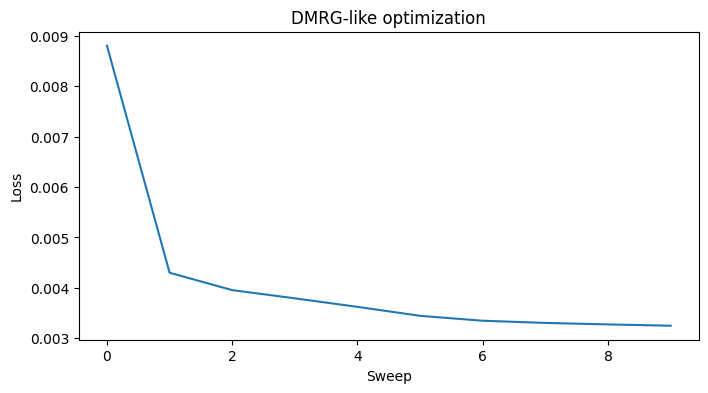

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

N = 10
M = 2 ** N

epsilon = 1e-1
noise = np.random.uniform(-epsilon, epsilon, size=M)

x2 = np.linspace(0, 1, M, endpoint=False)


y_exact =(
    0.5
    + 0.25 * np.sin(2 * np.pi * x2)
    + 0.125 * np.sin(4 * np.pi * x2)
    + 0.125 * np.sin(6 * np.pi * x2)
)


y = y_exact + noise


# QUANTICS ENCODING

def index_to_bits(i, N):
    return [int(b) for b in format(i, f'0{N}b')] #representación binaria de longitud N

X_bits = np.array([   #rejilla quantics, tensor f[n1,n2,...,nN],tensor rango N de dimensión 2
    index_to_bits(i, N)
    for i in range(M)
])

X_bits = torch.tensor(
    X_bits,
    dtype=torch.long
)

y_target = torch.tensor(
    y,
    dtype=torch.float32
)

# MPS INICIAL, A1[n1] A2[n2] A3[n3] ... AN[nN], se guardan N tensores pequeños

bond_dim = 8 #hiperparámetro clave, mide correlación/entrelazamiento

cores = []

for k in range(N): #Dl, Dr indices virtuales, 2 indice fisico

    Dl = 1 if k == 0 else bond_dim  #bordes abiertos
    Dr = 1 if k == N - 1 else bond_dim

    core = torch.nn.Parameter( #Inicializas los tensores aleatoriamente
        0.1 * torch.randn(
            Dl,
            2,
            Dr
        )
    )

    cores.append(core)

# PREDICCIÓN MPS
def predict_batch(X_bits, cores): #contrae secuencialmente el MPS siguiendo los bits de entrada.
    # primer core
    A0 = cores[0][:, X_bits[:, 0], :]

    # (1,batch,D) -> (batch,D)
    v = A0.squeeze(0)

    # contracción secuencial

    for k in range(1, len(cores)):

        Ak = cores[k][:, X_bits[:, k], :]

        # cambiar orden:
        # (Dl,batch,Dr) -> (batch,Dl,Dr)
        Ak = Ak.permute(1, 0, 2)

        # batch contraction
        v = torch.einsum(
            'bi,bij->bj',
            v,
            Ak
        )
    return v.squeeze()
def compute_loss():

    preds = predict_batch(X_bits, cores)

    return torch.mean(
        (preds - y_target) ** 2
    )

#  DMRG-LIKE TRAINING

epochs_per_tensor = 15
sweeps = 10

loss_history = []

for sweep in range(sweeps):


    # LEFT -> RIGHT SWEEP

    for site in range(N):

        optimizer = torch.optim.Adam(
            [cores[site]],
            lr=1e-2
        )

        for _ in range(epochs_per_tensor):

            optimizer.zero_grad()

            loss = compute_loss()

            loss.backward()

            optimizer.step()

    # RIGHT -> LEFT SWEEP

    for site in reversed(range(N)):

        optimizer = torch.optim.Adam(
            [cores[site]],
            lr=1e-2
        )

        for _ in range(epochs_per_tensor):

            optimizer.zero_grad()

            loss = compute_loss()

            loss.backward()

            optimizer.step()

    current_loss = compute_loss().item()

    loss_history.append(current_loss)

    print(
        f"Sweep {sweep:3d} | "
        f"Loss = {current_loss:.8f}"
    )

#PREDICCIÓN FINAL

with torch.no_grad():

    predictions = predict_batch(
        X_bits,
        cores
    ).numpy()

mse = np.mean(
    (predictions - y_exact) ** 2
)

print("\n================================")
print(f"MSE final: {mse:.8e}")
print("================================")

plt.figure(figsize=(12, 6))

plt.plot(
    x2,
    y_exact,
    label="Función exacta")
plt.plot(
    x2,
    y,
    alpha=0.3,
    label="Datos con ruido")
plt.plot(
    x2,
    predictions,
    '--',
    linewidth=2,
    label="MPS DMRG-like")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Regresión Quantics + MPS + DMRG-like training")
plt.legend()
plt.show()
plt.figure(figsize=(8, 4))

plt.plot(loss_history)
plt.xlabel("Sweep")
plt.ylabel("Loss")
plt.title("DMRG-like optimization")
plt.show()


Para ver si realmente mejora las predicciones o es irrelevante este método, se aplica a un problema de regresión de mayor escala, concretamente a un dataset de precios de viviendas. Se compara el nuevo método con un modelo de entrenamiento clásico y la codificación QUBO antes realizada.

# **DATASET**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("camnugent/california-housing-prices")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'california-housing-prices' dataset.
Path to dataset files: /kaggle/input/california-housing-prices


In [ ]:
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

csv_path = os.path.join(path, "housing.csv")
df = pd.read_csv(csv_path)

df = df.dropna()
print(df.head())
print(df.info())

# Seleccionamos las variables de entrada (Features) y la variable objetivo (Target), empezamos por 3
features_cols = ['median_income', 'total_rooms', 'housing_median_age']
target_col = 'median_house_value'

X_raw = df[features_cols].values
y_raw = df[target_col].values

scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X_raw)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y_raw.reshape(-1, 1)).flatten()



   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data

## **Feature map Continuos+ dmrg y mps**






Las variables de entrada se mantienen continuas y se proyectan a un espacio de características inspirado en la representación de estados cuánticos:**Feature map cuántico continuo**. Cada variable de entrada (x) se transforma en un vector bidimensional mediante las funciones trigonométricas:

($\phi_0(x) = \cos\left(\frac{\pi}{2}x\right))
(\phi_1(x) = \sin\left(\frac{\pi}{2}x\right))$

Esa transformación es exactamente el tipo de codificación que se utiliza en muchos algoritmos de Quantum Machine Learning.

Dataset cargado correctamente
Muestras totales: 8000
Train: 6400
Test : 1600
Número de variables: 5

Iniciando entrenamiento...

Sweep  1/12 | Loss = 0.025504
Sweep  2/12 | Loss = 0.023023
Sweep  3/12 | Loss = 0.022887
Sweep  4/12 | Loss = 0.022827
Sweep  5/12 | Loss = 0.022872
Sweep  6/12 | Loss = 0.022858
Sweep  7/12 | Loss = 0.022837
Sweep  8/12 | Loss = 0.022809
Sweep  9/12 | Loss = 0.022728
Sweep 10/12 | Loss = 0.022729
Sweep 11/12 | Loss = 0.022674
Sweep 12/12 | Loss = 0.022702

RESULTADOS FINALES
MAE  : $55,225.15
RMSE : $74,127.39
R²   : 0.5859
Tiempo total: 29.43 s


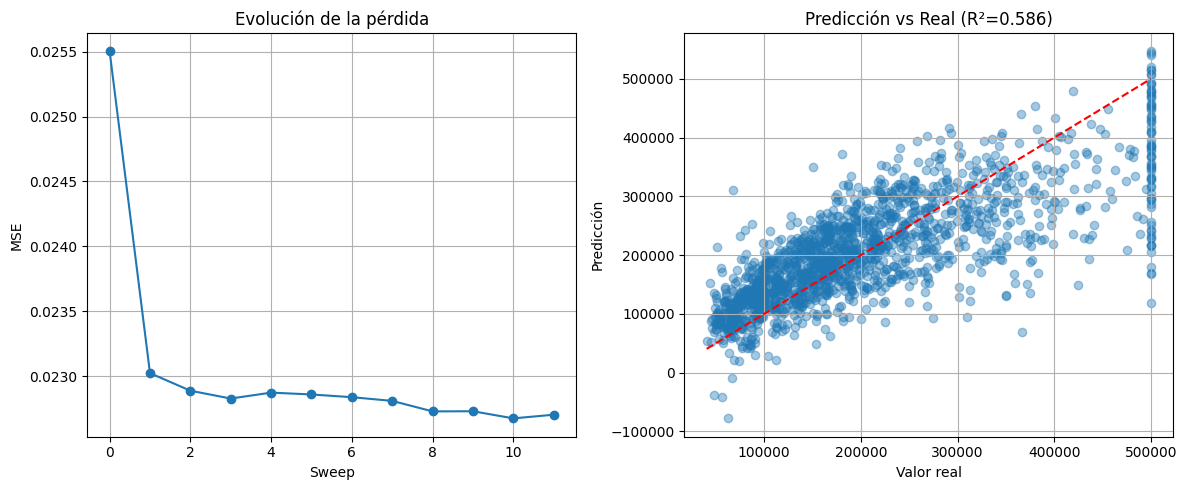

In [ ]:
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error


feature_cols = [
    'median_income',
    'total_rooms',
    'housing_median_age',
    'latitude',
    'longitude'
]

target_col = 'median_house_value'

sample_size = 8000

bond_dim = 8
epochs_per_tensor = 15
sweeps = 12


df_model = df[feature_cols + [target_col]].dropna()

df_model = df_model.sample(
    n=min(sample_size, len(df_model)),
    random_state=42
).reset_index(drop=True)

X = df_model[feature_cols].values
y = df_model[target_col].values.reshape(-1, 1)

# Train/Test Split

X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Escalado

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_np)
X_test_scaled = scaler_X.transform(X_test_np)

y_train_scaled = scaler_y.fit_transform(y_train_np)
y_test_scaled = scaler_y.transform(y_test_np)

# Tensores

X_train = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_target = torch.tensor(
    y_train_scaled.flatten(),
    dtype=torch.float32
)

# FEATURE MAP CUÁNTICO CONTINUO


def quantum_feature_map(X):

    phi_0 = torch.cos(np.pi / 2 * X)
    phi_1 = torch.sin(np.pi / 2 * X)

    return torch.stack(
        [phi_0, phi_1],
        dim=-1
    )

X_mapped = quantum_feature_map(X_train)

num_features = X_train.shape[1]
N = num_features

print("========================================")
print("Dataset cargado correctamente")
print(f"Muestras totales: {len(df_model)}")
print(f"Train: {len(X_train_np)}")
print(f"Test : {len(X_test_np)}")
print(f"Número de variables: {N}")
print("========================================")


# CONSTRUCCIÓN DEL MPS

cores = []

for k in range(N):

    Dl = 1 if k == 0 else bond_dim
    Dr = 1 if k == N - 1 else bond_dim

    core = torch.nn.Parameter(
        torch.randn(
            Dl,
            2,
            Dr
        ) * 0.1
    )

    cores.append(core)


# PREDICCIÓN MPS


def predict_batch(X_mapped, cores):

    phi_site0 = X_mapped[:, 0, :]

    v = torch.einsum(
        'idj,bd->bj',
        cores[0],
        phi_site0
    )

    for k in range(1, len(cores)):

        phi_sitek = X_mapped[:, k, :]

        v = torch.einsum(
            'bi,idj,bd->bj',
            v,
            cores[k],
            phi_sitek
        )

    return v.squeeze()

def compute_loss():

    preds = predict_batch(
        X_mapped,
        cores
    )

    return torch.mean(
        (preds - y_target) ** 2
    )



start_time = time.perf_counter() #se cuantifica el tiempo de entrenamiento

loss_history = []

print("\nIniciando entrenamiento...\n")

for sweep in range(sweeps):

    # LEFT -> RIGHT

    for site in range(N):

        optimizer = torch.optim.Adam(
            [cores[site]],
            lr=2e-2
        )

        for _ in range(epochs_per_tensor):

            optimizer.zero_grad()

            loss = compute_loss()

            loss.backward()

            optimizer.step()

    # RIGHT -> LEFT

    for site in reversed(range(N)):

        optimizer = torch.optim.Adam(
            [cores[site]],
            lr=2e-2
        )

        for _ in range(epochs_per_tensor):

            optimizer.zero_grad()

            loss = compute_loss()

            loss.backward()

            optimizer.step()

    current_loss = compute_loss().item()

    loss_history.append(current_loss)

    print(
        f"Sweep {sweep+1:2d}/{sweeps} | "
        f"Loss = {current_loss:.6f}"
    )

elapsed_time = time.perf_counter() - start_time


# EVALUACIÓN SOBRE TEST


X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

X_test_mapped = quantum_feature_map(
    X_test_tensor
)

with torch.no_grad():

    pred_test_scaled = predict_batch(
        X_test_mapped,
        cores
    ).numpy()

# Volver a escala real

pred_test_real = scaler_y.inverse_transform(
    pred_test_scaled.reshape(-1, 1)
).flatten()

y_test_real = scaler_y.inverse_transform(
    y_test_scaled
).flatten()

# MÉTRICAS


mae = np.mean(
    np.abs(
        pred_test_real - y_test_real
    )
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_real,
        pred_test_real
    )
)

r2 = r2_score(
    y_test_real,
    pred_test_real
)

print("\n========================================")
print("RESULTADOS FINALES")
print("========================================")
print(f"MAE  : ${mae:,.2f}")
print(f"RMSE : ${rmse:,.2f}")
print(f"R²   : {r2:.4f}")
print(f"Tiempo total: {elapsed_time:.2f} s")
print("========================================")

# ============================================================
# GRÁFICAS
# ============================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    loss_history,
    marker='o'
)

plt.xlabel("Sweep")
plt.ylabel("MSE")
plt.title("Evolución de la pérdida")
plt.grid(True)

plt.subplot(1, 2, 2)

plt.scatter(
    y_test_real,
    pred_test_real,
    alpha=0.4
)

plt.plot(
    [y_test_real.min(), y_test_real.max()],
    [y_test_real.min(), y_test_real.max()],
    'r--'
)

plt.xlabel("Valor real")
plt.ylabel("Predicción")
plt.title(f"Predicción vs Real (R²={r2:.3f})")
plt.grid(True)

plt.tight_layout()
plt.show()

Se observa que al **incrementar la bond dimension** del modelo desde 16 hasta 32, el rendimiento en test empeora.

El incremento de la bond dimension aumenta significativamente el número de parámetros y la capacidad expresiva del modelo. Sin embargo, también incrementa la complejidad del paisaje de optimización, introduciendo más mínimos locales y dificultando la convergencia del algoritmo de entrenamiento.

Además, el esquema de optimización utilizado (basado en barridos tipo DMRG combinados con optimización de gradiente) no escala de forma óptima con dimensiones de enlace elevadas, lo que puede provocar inestabilidad numérica y soluciones subóptimas.

## **QUANTICS TENSOR TRAIN**

A diferencia de los Feature Maps continuos y de la rigidez de los modelos lineales discretos (QUBO), este bloque implementa una representación **Quantics Tensor Train (QTT)**. Se utiliza especialmente en la resolución de ecuaciones diferenciales, pero aquí se ha implementado en el campo del **Machine Learning Supervisado con datos ruidosos reales**.

El objetivo es predecir el valor medio de viviendas a partir de variables socioeconómicas.

El algoritmo exprea cada variable continua del dataset en sus componentes binarios (bits), transformando el espacio en una rejilla fractal de alta resolución ($2^b$ intervalos por dimensión). Cada bit es mapeado de forma diferenciable a un vector de estado cuántico continuo $\begin{bmatrix}1\\0\end{bmatrix}$ o $\begin{bmatrix}0\\1\end{bmatrix}$, entrelazando las variables en una única cadena de espines virtuales a través de un **Matrix Product State (MPS)**.

Cada variable se discretiza utilizando 5 bits de precisión, lo que equivale a una resolución de $2^5=32$ niveles por característica.

Cada valor continuo se convierte primero en un entero escalado y posteriormente en una representación binaria. Cada bit se codifica como un vector de dimensión 2 equivalente a una base computacional:

$0 \to (1, 0)
1\to (0, 1)$

El conjunto completo de variables genera una cadena de longitud total 15 (5 variables × 5 bits). Esta representación permite reinterpretar los datos como un tensor de alta dimensión estructurado jerárquicamente.



Al optimizar los núcleos locales mediante barridos estilo **DMRG (Density Matrix Renormalization Group)**, el modelo procesa la información de forma multiescala: los primeros sitios de la cadena absorben las macro-tendencias globales, mientras que los últimos refinan los detalles microscópicos no lineales. Al comprimir la información bajo una dimensión de enlace fija (`bond_dim`), el MPS actúa como un cuello de botella regularizador,  y es inmune al sobreajuste (*overfitting*), a diferencia de los métodos clásicos.

**MAE (Mean Absolute Error)**: mide el error medio absoluto entre las predicciones del modelo y los valores reales. No distingue entre errores grandes o pequeños.

**RMSE (Root Mean Squared Error)**: es la raíz del error cuadrático medio.Penaliza errores grandes, es decir, si el modelo falla mucho en algunos casos, el RMSE sube bastante.

**R² (coeficiente de determinación)**: mide la proporción de varianza explicada por el modelo, en otras palabras, mide qué tan bien explica el modelo la variabilidad de los datos. 1.0 → perfecto
0.0 → igual que predecir la media siempre


Dataset Quantics cargado correctamente
Sitios QTT: 25
Train: 6400 | Test: 1600

Iniciando entrenamiento QTT...

Sweep  1/10 | Loss = 0.084691
Sweep  2/10 | Loss = 0.021971
Sweep  3/10 | Loss = 0.018472
Sweep  4/10 | Loss = 0.015973
Sweep  5/10 | Loss = 0.015254
Sweep  6/10 | Loss = 0.015194
Sweep  7/10 | Loss = 0.014938
Sweep  8/10 | Loss = 0.014873
Sweep  9/10 | Loss = 0.014875
Sweep 10/10 | Loss = 0.014790

RESULTADOS FINALES QTT
MAE  : $42,137.76
RMSE : $60,917.81
R²   : 0.6961
Tiempo: 362.55 s


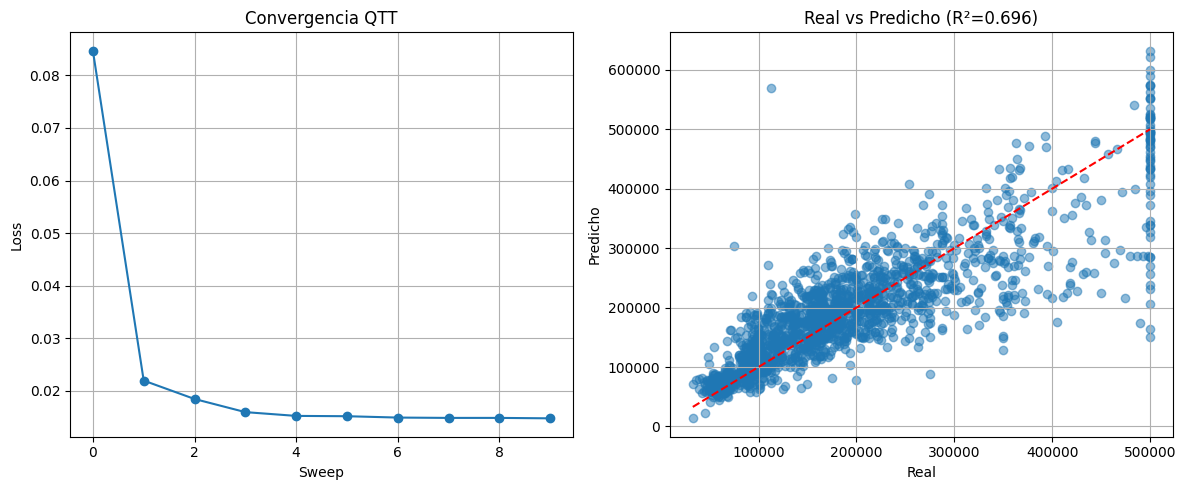

In [ ]:
import os
import time
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error


csv_path = os.path.join(path, "housing.csv")
df = pd.read_csv(csv_path)
df = df.dropna()

features_cols = [
    'median_income',
    'total_rooms',
    'housing_median_age',
    'latitude',
    'longitude'
]

target_col = 'median_house_value'

X_raw = df[features_cols].values
y_raw = df[target_col].values.reshape(-1, 1)


scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(X_raw)
y_scaled = scaler_y.fit_transform(y_raw).flatten()


sample_size = 8000

X_scaled = X_scaled[:sample_size]
y_scaled = y_scaled[:sample_size]

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_scaled,
    y_scaled,
    test_size=0.2,
    random_state=42
)


# QUANTICS ENCODING (QTT)


bits_per_feature = 5
num_features = X_train_raw.shape[1]
N = num_features * bits_per_feature

def float_to_quantics_vectors(X_matrix, num_bits):

    batch_size, n_feats = X_matrix.shape
    total_sites = n_feats * num_bits

    quantics_tensor = torch.zeros(
        (batch_size, total_sites, 2),
        dtype=torch.float32
    )

    for i in range(batch_size):
        site_idx = 0

        for f in range(n_feats):

            val_int = int(X_matrix[i, f] * (2**num_bits - 1))
            bits_str = format(val_int, f'0{num_bits}b')

            for bit in bits_str:

                if bit == '0':
                    quantics_tensor[i, site_idx, 0] = 1.0
                else:
                    quantics_tensor[i, site_idx, 1] = 1.0

                site_idx += 1

    return quantics_tensor

X_train = float_to_quantics_vectors(X_train_raw, bits_per_feature)
X_test = float_to_quantics_vectors(X_test_raw, bits_per_feature)

y_train = torch.tensor(y_train_raw, dtype=torch.float32)

print("\nDataset Quantics cargado correctamente")
print(f"Sitios QTT: {N}")
print(f"Train: {len(X_train)} | Test: {len(X_test)}")


# MPS / QTT MODEL

bond_dim = 8

cores = []

for k in range(N):

    Dl = 1 if k == 0 else bond_dim
    Dr = 1 if k == N - 1 else bond_dim

    scale = 1.0 / np.sqrt(Dl)

    core = torch.nn.Parameter(
        torch.randn(Dl, 2, Dr) * scale * 0.5
    )

    cores.append(core)


# CONTRACCIÓN QTT


def predict_batch(X_qtt, cores):

    phi_0 = X_qtt[:, 0, :]
    v = torch.einsum('idj,bd->bj', cores[0], phi_0)

    for k in range(1, len(cores)):

        phi_k = X_qtt[:, k, :]

        v = torch.einsum(
            'bi,idj,bd->bj',
            v,
            cores[k],
            phi_k
        )

    return v.squeeze()

def compute_loss():

    preds = predict_batch(X_train, cores)

    return torch.mean((preds - y_train) ** 2)

# ENTRENAMIENTO


start_time = time.perf_counter()

epochs_per_tensor = 10
sweeps = 10

loss_history = []

print("\nIniciando entrenamiento QTT...\n")

for sweep in range(sweeps):

    # LEFT -> RIGHT
    for site in range(N):

        optimizer = torch.optim.Adam([cores[site]], lr=1e-2)

        for _ in range(epochs_per_tensor):

            optimizer.zero_grad()
            loss = compute_loss()
            loss.backward()
            optimizer.step()

    # RIGHT -> LEFT
    for site in reversed(range(N)):

        optimizer = torch.optim.Adam([cores[site]], lr=1e-2)

        for _ in range(epochs_per_tensor):

            optimizer.zero_grad()
            loss = compute_loss()
            loss.backward()
            optimizer.step()

    current_loss = compute_loss().item()
    loss_history.append(current_loss)

    print(f"Sweep {sweep+1:2d}/{sweeps} | Loss = {current_loss:.6f}")

elapsed_time = time.perf_counter() - start_time


# EVALUACIÓN TEST


with torch.no_grad():

    preds_test_scaled = predict_batch(X_test, cores).numpy()

preds_test_real = scaler_y.inverse_transform(
    preds_test_scaled.reshape(-1, 1)
).flatten()

y_test_real = scaler_y.inverse_transform(
    y_test_raw.reshape(-1, 1)
).flatten()


# MÉTRICAS


mae = np.mean(np.abs(preds_test_real - y_test_real))

rmse = np.sqrt(
    mean_squared_error(y_test_real, preds_test_real)
)

r2 = r2_score(y_test_real, preds_test_real)

print("\n========================================")
print("RESULTADOS FINALES QTT")
print("========================================")
print(f"MAE  : ${mae:,.2f}")
print(f"RMSE : ${rmse:,.2f}")
print(f"R²   : {r2:.4f}")
print(f"Tiempo: {elapsed_time:.2f} s")
print("========================================")


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(loss_history, marker='o')
plt.title("Convergencia QTT")
plt.xlabel("Sweep")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(y_test_real, preds_test_real, alpha=0.5)
plt.plot(
    [y_test_real.min(), y_test_real.max()],
    [y_test_real.min(), y_test_real.max()],
    'r--'
)
plt.title(f"Real vs Predicho (R²={r2:.3f})")
plt.xlabel("Real")
plt.ylabel("Predicho")
plt.grid(True)

plt.tight_layout()
plt.show()

## **Regresión mediante Smooth Quantics Embedding y Matrix Product States (MPS)**

A diferencia de enfoques anteriores basados en codificación binaria, en este caso se utiliza una transformación continua de las variables de entrada.

**Smooth quantics**: El smooth quantics embedding es una variante continua del encoding tipo Quantics/QTT en la que cada variable no se discretiza en bits binarios, sino que se proyecta en un conjunto de funciones suaves multiescala del tipo **sin(2kπx)** y **cos(2kπx)**, es decir, cada característica se proyecta en un espacio de alta dimensión mediante una expansión en funciones trigonométricas de múltiples frecuencias.


Este modelo combina una representación de características basada en funciones periódicas (**tipo Fourier-like embedding**) con una estructura tensorial eficiente, permitiendo que el MPS capture correlaciones a distintas escalas sin depender de una binarización dura del espacio de entrada. A diferencia del quantics clásico, donde la estructura depende de la codificación binaria exacta del número, el smooth quantics preserva continuidad y mejora la estabilidad del entrenamiento variacional tipo DMRG. En la práctica, esto reduce la sensibilidad a la discretización y facilita la optimización de los tensores, lo que se traduce en una convergencia más rápida y mejores métricas de generalización, como se observa en la reducción del MSE y del MAE respecto al encoding quantics estándar.

Entre las arquitecturas estudiadas, el modelo basado en Smooth Quantics Embedding combinado con Matrix Product States obtuvo los mejores resultados. La utilización de funciones sinusoidales para representar las variables continuas permitió preservar la información original de forma más eficiente que la discretización binaria empleada en Quantics Tensor Train. Como consecuencia, se obtuvo un coeficiente de determinación R² = 0.60 y un error medio absoluto de aproximadamente 45.500 dólares, superando el rendimiento de las variantes tensoriales evaluadas previamente.

En esta versión del modelo se han introducido varias mejoras respecto al prototipo inicial. El smooth quantics embedding se implementa mediante **operaciones vectorizadas de PyTorch**, eliminando los bucles explícitos y acelerando significativamente el preprocesado. El modelo tensorial se encapsula en una clase **nn.Module**, lo que permite optimizar simultáneamente todos los tensores de la red mediante retropropagación global. También se incorpora **entrenamiento con mini-batches** usando **DataLoader**, mejorando la estabilidad numérica y la eficiencia computacional. En conjunto, estos cambios transforman el código desde una prueba de concepto basada en actualizaciones locales de cada tensor hacia una implementación más cercana a los estándares modernos de aprendizaje profundo y redes tensoriales

Quantics smooth encoding: 25 sites

Entrenando MPS con optimización conjunta extendida...
Epoch 10/200 | Loss = 0.079266 | LR = 0.00200
Epoch 20/200 | Loss = 0.011194 | LR = 0.00200
Epoch 30/200 | Loss = 0.007811 | LR = 0.00200
Epoch 40/200 | Loss = 0.007200 | LR = 0.00200
Epoch 50/200 | Loss = 0.006375 | LR = 0.00200
Epoch 60/200 | Loss = 0.005822 | LR = 0.00100
Epoch 70/200 | Loss = 0.005672 | LR = 0.00050
Epoch 80/200 | Loss = 0.005537 | LR = 0.00025
Epoch 90/200 | Loss = 0.005522 | LR = 0.00013
Epoch 100/200 | Loss = 0.005470 | LR = 0.00006
Epoch 110/200 | Loss = 0.005457 | LR = 0.00003
Epoch 120/200 | Loss = 0.005451 | LR = 0.00002
Epoch 130/200 | Loss = 0.005442 | LR = 0.00001
Epoch 140/200 | Loss = 0.005440 | LR = 0.00000
Epoch 150/200 | Loss = 0.005439 | LR = 0.00000
Epoch 160/200 | Loss = 0.005439 | LR = 0.00000
Epoch 170/200 | Loss = 0.005439 | LR = 0.00000
Epoch 180/200 | Loss = 0.005439 | LR = 0.00000
Epoch 190/200 | Loss = 0.005439 | LR = 0.00000
Epoch 200/200 | Loss = 0.0

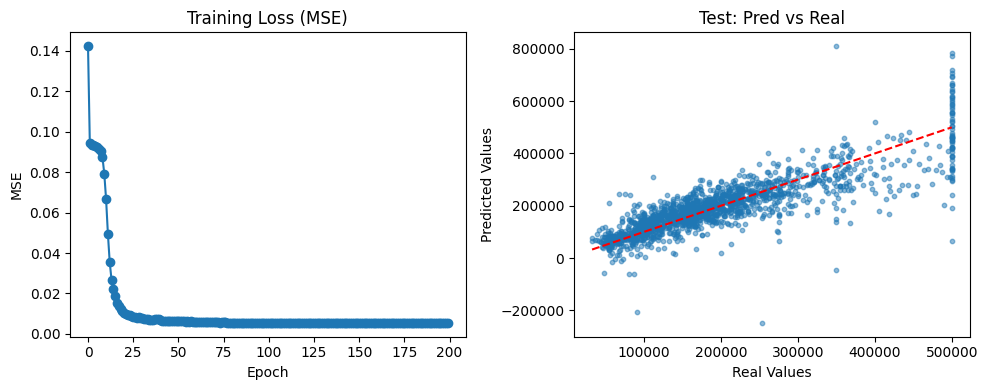

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

import time

features_cols = ['median_income', 'total_rooms',
                 'housing_median_age', 'latitude', 'longitude']
target_col = 'median_house_value'

X_raw = df[features_cols].values
y_raw = df[target_col].values


sample_size = 8000

X_raw = X_raw[:sample_size]
y_raw = y_raw[:sample_size]

# Separar en Train y Test ANTES de normalizar (para evitar data leakage)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

# Normalización
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_raw)
y_train_scaled = scaler_y.fit_transform(y_train_raw.reshape(-1, 1)).flatten()

X_test_scaled = scaler_X.transform(X_test_raw)
y_test_scaled = scaler_y.transform(y_test_raw.reshape(-1, 1)).flatten()
# Convertir a tensores
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)


def smooth_quantics_embedding_vectorized(X, num_bits=5):


    batch, n_feats = X.shape

    # Crear vector de frecuencias: [pi, 2pi, 4pi, ...]
    k = torch.arange(num_bits, dtype=torch.float32, device=X.device)
    freqs = (2 ** k) * torch.pi

    # Expandir X para multiplicar por las frecuencias
    # X shape: (batch, n_feats, 1) -> args shape: (batch, n_feats, num_bits)
    args = X.unsqueeze(-1) * freqs

    sin_vals = torch.sin(args)
    cos_vals = torch.cos(args)

    # Apilar y aplanar
    # shape resultante: (batch, n_feats * num_bits, 2)
    tensor = torch.stack([sin_vals, cos_vals], dim=-1)
    return tensor.reshape(batch, -1, 2)

bits_per_feature = 5
X_train_q = smooth_quantics_embedding_vectorized(X_train_t, bits_per_feature)
N_sites = X_train_q.shape[1]
print(f"Quantics smooth encoding: {N_sites} sites")

# Crear DataLoader para usar mini-batches
dataset = TensorDataset(X_train_q, y_train_t)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)


# MODELO MPS ENCAPSULADO

class SmoothQuanticsMPS(nn.Module):
    def __init__(self, N, bond_dim):
        super().__init__()
        self.N = N
        self.cores = nn.ParameterList()

        for k in range(N):
            Dl = 1 if k == 0 else bond_dim
            Dr = 1 if k == N - 1 else bond_dim
            scale = 1.0 / np.sqrt(Dl)

            # Inicialización de parámetros
            core = nn.Parameter(torch.randn(Dl, 2, Dr) * scale)
            self.cores.append(core)

    def forward(self, X):
        # Contracción de la red tensorial
        v = torch.einsum('sdi,bd->bi', self.cores[0], X[:, 0, :])
        for k in range(1, self.N):
            v = torch.einsum('bi,idj,bd->bj', v, self.cores[k], X[:, k, :])
        return v.squeeze(-1)


bond_dim =8
model = SmoothQuanticsMPS(N=N_sites, bond_dim=bond_dim)


# ENTRENAMIENTO (Optimización Conjunta con Mini-batches)

# Sube el LR a 2e-3
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
#criterion = nn.MSELoss()
criterion = nn.HuberLoss()
# Reduce el LR a la mitad si la pérdida se estanca por 3 épocas
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

epochs = 200
loss_history = []
start_time = time.perf_counter()
print("\nEntrenando MPS con optimización conjunta extendida...")
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_X, batch_y in dataloader:
        optimizer.zero_grad()
        preds = model(batch_X)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * batch_X.size(0)

    epoch_loss /= len(dataloader.dataset)
    loss_history.append(epoch_loss)
    scheduler.step(epoch_loss) # Actualiza el scheduler

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Loss = {epoch_loss:.6f} | LR = {optimizer.param_groups[0]['lr']:.5f}")





total_time = time.perf_counter() - start_time

model.eval()

with torch.no_grad():

    X_test_q = smooth_quantics_embedding_vectorized(
        X_test_t,
        bits_per_feature
    )

    pred_scaled = model(X_test_q).numpy()

pred_real = scaler_y.inverse_transform(
    pred_scaled.reshape(-1, 1)
).flatten()

y_real = y_test_raw

mae = np.mean(
    np.abs(pred_real - y_real)
)

rmse = np.sqrt(
    mean_squared_error(
        y_real,
        pred_real
    )
)

r2 = r2_score(
    y_real,
    pred_real
)

print("\n====================================")
print("RESULTADOS FINALES")
print("====================================")
print(f"MAE  : ${mae:,.2f}")
print(f"RMSE : ${rmse:,.2f}")
print(f"R²   : {r2:.4f}")
print(f"Tiempo: {total_time:.2f} s")
print("====================================")


plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(loss_history, marker='o')
plt.title("Training Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.subplot(1,2,2)
plt.scatter(y_test_raw, pred_real, alpha=0.5, s=10)
plt.plot([y_test_raw.min(), y_test_raw.max()],
         [y_test_raw.min(), y_test_raw.max()], 'r--')
plt.title("Test: Pred vs Real")
plt.xlabel("Real Values")
plt.ylabel("Predicted Values")

plt.tight_layout()
plt.show()

## QUBO, Simulated Annealing

Este código implementa un modelo de regresión lineal formulado como un problema QUBO (Quadratic Unconstrained Binary Optimization) para predecir el valor medio de las viviendas de California a partir de cinco variables de entrada. Primero, los datos se normalizan y se dividen en conjuntos de entrenamiento y prueba. A continuación, los coeficientes de la regresión se codifican mediante variables binarias utilizando un **esquema de representación discreta**, transformando el problema clásico de mínimos cuadrados en una **función objetivo cuadrática **expresada como una matriz QUBO. Esta matriz se optimiza mediante **Simulated Annealing usando la librería neal**, obteniendo una configuración binaria que posteriormente se decodifica para recuperar los pesos continuos del modelo. Finalmente, dichos pesos se utilizan para realizar predicciones sobre los conjuntos de entrenamiento y prueba, evaluando el rendimiento mediante métricas como MAE, RMSE y R², además de analizar gráficamente la relación entre los precios reales y los predichos. Aunque la optimización está inspirada en técnicas utilizadas en computación cuántica, en este caso se ejecuta íntegramente sobre hardware clásico.

Generando la matriz QUBO vectorizada con datos de Entrenamiento...
Lanzando Simulated Annealing para 30 qubits...

Pesos óptimos decodificados (w): [ 1.125  0.25   0.    -0.875 -0.75   0.75 ]
RESULTADOS QUBO
TRAIN MAE  : $52,389.12
TRAIN RMSE : $71,627.87
TRAIN R²   : 0.5744
TEST MAE   : $51,542.71
TEST RMSE  : $70,184.39
TEST R²    : 0.5966
Tiempo     : 3.54 s


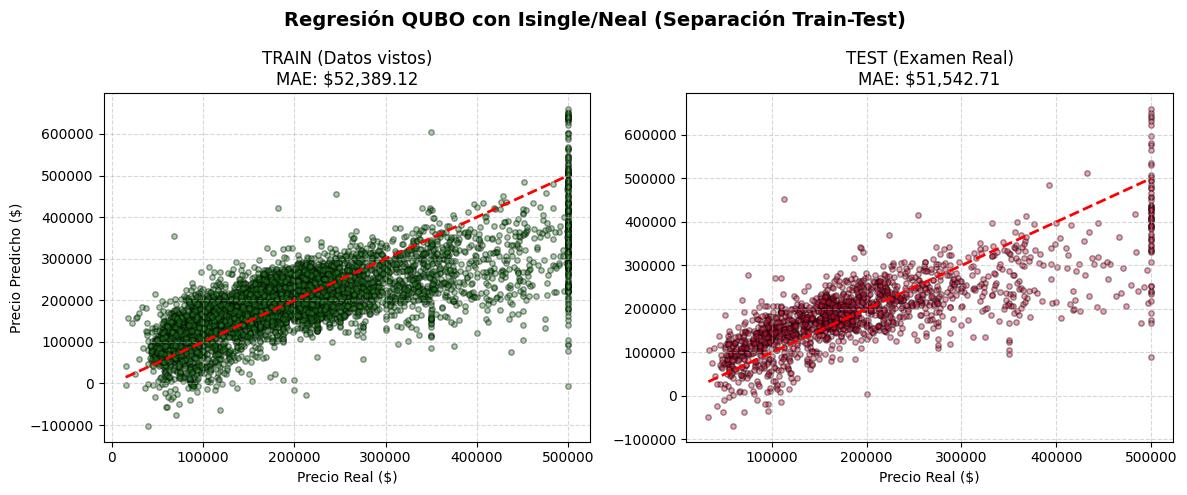

In [ ]:
import os
import pandas as pd
import numpy as np
import neal
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import time
from sklearn.metrics import mean_squared_error


csv_path = os.path.join(path, "housing.csv")
df = pd.read_csv(csv_path).dropna()

features_cols = ['median_income', 'total_rooms', 'housing_median_age', 'latitude', 'longitude']
target_col = 'median_house_value'


sample_size = 8000
df_sample = df.iloc[:sample_size]

X_raw = df_sample[features_cols].values
y_raw = df_sample[target_col].values

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.20, random_state=42
)


scaler_X = MinMaxScaler()
X_train_scaled = scaler_X.fit_transform(X_train_raw)
X_test_scaled = scaler_X.transform(X_test_raw)

scaler_y = MinMaxScaler()
y_train_scaled = scaler_y.fit_transform(y_train_raw.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test_raw.reshape(-1, 1)).flatten()

X_train_bias = np.hstack([X_train_scaled, np.ones((X_train_scaled.shape[0], 1))]) #aprender el término independiente
X_test_bias = np.hstack([X_test_scaled, np.ones((X_test_scaled.shape[0], 1))])


Phi = X_train_bias.T
y = y_train_scaled

m = Phi.shape[0]  # 6 parámetros (5 features + 1 bias)
encoding_vec = build_encoding_vector(alpha=3, beta=0)
T_matrix = build_T(m, encoding_vec)

print("Generando la matriz QUBO vectorizada con datos de Entrenamiento...")
Q_tilde = build_qubo(Phi, y, T_matrix)


Q_dict = {
    (i, j): Q_tilde[i, j]
    for i in range(Q_tilde.shape[0])
    for j in range(Q_tilde.shape[1])
    if Q_tilde[i, j] != 0
}


print(f"Lanzando Simulated Annealing para {Q_tilde.shape[0]} qubits...")
start_time = time.perf_counter()
sampler = neal.SimulatedAnnealingSampler()
sampleset = sampler.sample_qubo(Q_dict, num_reads=500)
total_time = time.perf_counter() - start_time


# Extraemos la mejor configuración cuántica de espines binarios
best_sample = sampleset.first.sample
u_binario = np.array([best_sample[i] for i in range(len(best_sample))])

# Decodificamos la solución binaria para obtener los pesos continuos
pesos_qubo = decode_solution(T_matrix, u_binario)
print("\nPesos óptimos decodificados (w):", pesos_qubo)


# Predicción Lineal: Y_pred = X * w
pred_train_scaled = X_train_bias @ pesos_qubo
pred_test_scaled = X_test_bias @ pesos_qubo

# Desescalamos ambas predicciones a dólares reales de California
pred_train_real = scaler_y.inverse_transform(pred_train_scaled.reshape(-1, 1)).flatten()
pred_test_real = scaler_y.inverse_transform(pred_test_scaled.reshape(-1, 1)).flatten()

y_train_real = y_train_raw
y_test_real = y_test_raw

# Calculamos el error absoluto medio (MAE)
mae_train = np.mean(np.abs(pred_train_real - y_train_real))
mae_test = np.mean(np.abs(pred_test_real - y_test_real))
rmse_train = np.sqrt(
    mean_squared_error(
        y_train_real,
        pred_train_real
    )
)

rmse_test = np.sqrt(
    mean_squared_error(
        y_test_real,
        pred_test_real
    )
)

r2_train = r2_score(
    y_train_real,
    pred_train_real
)

r2_test = r2_score(
    y_test_real,
    pred_test_real
)


print("RESULTADOS QUBO")

print(f"TRAIN MAE  : ${mae_train:,.2f}")
print(f"TRAIN RMSE : ${rmse_train:,.2f}")
print(f"TRAIN R²   : {r2_train:.4f}")

print(f"TEST MAE   : ${mae_test:,.2f}")
print(f"TEST RMSE  : ${rmse_test:,.2f}")
print(f"TEST R²    : {r2_test:.4f}")


print(f"Tiempo     : {total_time:.2f} s")

print("======================================")

plt.figure(figsize=(12, 5))

# Subplot 1: Train
plt.subplot(1, 2, 1)
plt.scatter(y_train_real, pred_train_real, s=15, alpha=0.4, color='forestgreen', edgecolors='k')
plt.plot([y_train_real.min(), y_train_real.max()], [y_train_real.min(), y_train_real.max()], 'r--', linewidth=2)
plt.xlabel("Precio Real ($)")
plt.ylabel("Precio Predicho ($)")
plt.title(f"TRAIN (Datos vistos)\nMAE: ${mae_train:,.2f}")
plt.grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Test
plt.subplot(1, 2, 2)
plt.scatter(y_test_real, pred_test_real, s=15, alpha=0.4, color='crimson', edgecolors='k')
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', linewidth=2)
plt.xlabel("Precio Real ($)")
plt.title(f"TEST (Examen Real)\nMAE: ${mae_test:,.2f}")
plt.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Regresión QUBO con Isingle/Neal (Separación Train-Test)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## **Machine learning clásico**

Este código implementa un modelo de **Random Forest Regressor** , un método clásico de machine learning basado en la combinación de múltiples árboles de decisión para realizar predicciones de regresión.



RANDOM FOREST RESULTS
TRAIN MAE  : $10,000.59
TRAIN RMSE : $16,321.33
TRAIN R²   : 0.9779

TEST MAE   : $26,342.45
TEST RMSE  : $42,173.94
TEST R²    : 0.8543

Training Time : 2.95 s
Prediction Time : 0.2348 s


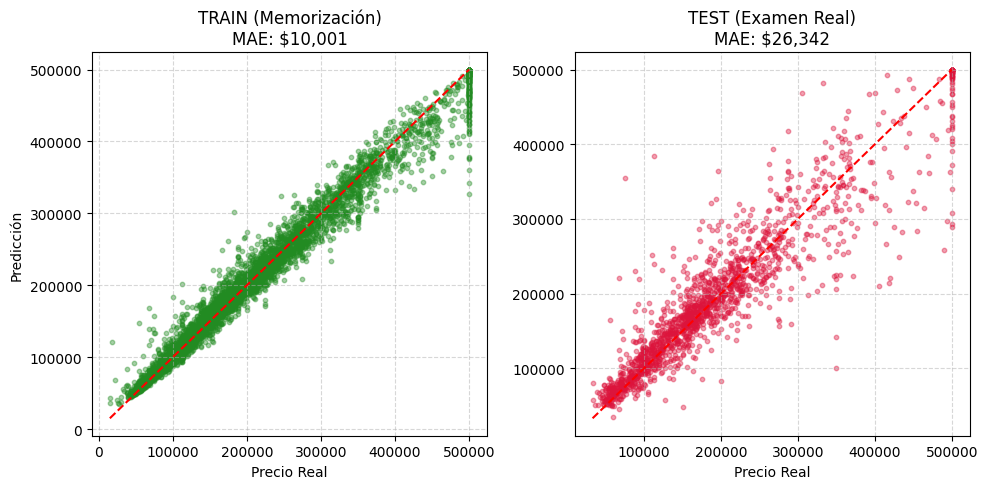

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import time
from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

csv_path = os.path.join(path, "housing.csv")
df = pd.read_csv(csv_path).dropna()

features_cols = ['median_income', 'total_rooms', 'housing_median_age', 'latitude', 'longitude']
target_col = 'median_house_value'


sample_size = 8000
df_sample = df.iloc[:sample_size]

X_raw = df_sample[features_cols].values
y_raw = df_sample[target_col].values


X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.20, random_state=42
)

scaler_X = MinMaxScaler()
X_train = scaler_X.fit_transform(X_train_raw)
X_test = scaler_X.transform(X_test_raw)

scaler_y = MinMaxScaler()
y_train = scaler_y.fit_transform(y_train_raw.reshape(-1, 1)).flatten()
y_test = scaler_y.transform(y_test_raw.reshape(-1, 1)).flatten()


# ENTRENAMIENTO DEL MODELO CLÁSICO (RANDOM FOREST)
start_time = time.perf_counter()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

train_time = time.perf_counter() - start_time

start_pred = time.perf_counter()
pred_train_scaled = rf_model.predict(X_train)
prediction_time = time.perf_counter() - start_pred
pred_train_real = scaler_y.inverse_transform(pred_train_scaled.reshape(-1, 1)).flatten()


pred_test_scaled = rf_model.predict(X_test)
pred_test_real = scaler_y.inverse_transform(pred_test_scaled.reshape(-1, 1)).flatten()

y_train_real = scaler_y.inverse_transform(y_train.reshape(-1, 1)).flatten()
y_test_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()

mae_train = np.mean(np.abs(pred_train_real - y_train_real))
mae_test = np.mean(np.abs(pred_test_real - y_test_real))
rmse_train = np.sqrt(
    mean_squared_error(
        y_train_real,
        pred_train_real
    )
)

rmse_test = np.sqrt(
    mean_squared_error(
        y_test_real,
        pred_test_real
    )
)

r2_train = r2_score(
    y_train_real,
    pred_train_real
)

r2_test = r2_score(
    y_test_real,
    pred_test_real
)

print("RANDOM FOREST RESULTS")

print(f"TRAIN MAE  : ${mae_train:,.2f}")
print(f"TRAIN RMSE : ${rmse_train:,.2f}")
print(f"TRAIN R²   : {r2_train:.4f}")

print()

print(f"TEST MAE   : ${mae_test:,.2f}")
print(f"TEST RMSE  : ${rmse_test:,.2f}")
print(f"TEST R²    : {r2_test:.4f}")

print()

print(f"Training Time : {train_time:.2f} s")
print(f"Prediction Time : {prediction_time:.4f} s")




plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_train_real, pred_train_real, alpha=0.4, color='forestgreen', s=10)
plt.plot([y_train_real.min(), y_train_real.max()], [y_train_real.min(), y_train_real.max()], 'r--')
plt.title(f"TRAIN (Memorización)\nMAE: ${mae_train:,.0f}")
plt.xlabel("Precio Real")
plt.ylabel("Predicción")
plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.scatter(y_test_real, pred_test_real, alpha=0.4, color='crimson', s=10)
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--')
plt.title(f"TEST (Examen Real)\nMAE: ${mae_test:,.0f}")
plt.xlabel("Precio Real")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Los modelos basados en redes tensoriales y formulaciones QUBO no superan en precisión a métodos clásicos como Random Forest en este dataset, pero ofrecen un marco alternativo interesante en términos de estructura matemática, escalabilidad potencial y conexión con hardware cuántico

# HARDWARE CUÁNTICO

Pasar de MPS/QTT clásico a un**Variational Quantum Circuit (VQC)** equivalente.

QTT / MPS	VQC (cuántico)

cores[k]---	capa de puertas cuánticas

bond_dim---	número de capas (depth)

einsum contraction---	evolución del circuito

feature map---	encoding cuántico

output tensor---	expectation value

In [ ]:
!pip install pennylane pennylane-lightning torch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 68.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 88.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 110.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 14.7 MB/s eta 0:00:00


# TRAINSUM


Regresión Quantics con trainsum

Equivalente al pipeline manual MPS + DMRG-like training:
  - Quantics encoding (índice binario → tensor de rango N, dim física 2)
  - Tensor Train con bond_dim controlado
  - Ajuste por aproximación variacional (sweeps DMRG-like internos)




In [ ]:
!pip install trainsum

ERROR: Ignored the following versions that require a different python version: 0.0.1 Requires-Python >=3.14; 0.0.2 Requires-Python >=3.14
ERROR: Could not find a version that satisfies the requirement trainsum (from versions: none)
ERROR: No matching distribution found for trainsum
